# Retail Sales Data Analysis

**Name:** Hermella Gebrehawaryat  
**Track:** Data Analytics  
**Task:** Exploratory Data Analysis (EDA) on Retail Sales Data

**Tools:** Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook

## Project Overview

This project focuses on performing Exploratory Data Analysis (EDA) on retail sales data to identify sales trends, understand customer demographics, evaluate product category performance, and uncover actionable business insights.

## Project Objective

The main objective is to explore the dataset, identify meaningful patterns and relationships, and provide data-driven recommendations that can support better business decision-making.

In [1]:
#used for data manipulation, cleaning, and analysis
import pandas as pd
#used for creating statistical visualizations, such as count plots and heatmaps
import seaborn as sns
#used for creating and customizing charts and graphs
import matplotlib.pyplot as plt

function named wrangle() takes a file path as an argument, reads the CSV file using Pandas, and returns the dataset as a DataFrame for further analysis

## Data Loading and Initial Inspection

In [2]:
def wrangle(filepath):
    df = pd.read_csv(filepath)
    return df

In [3]:
df= wrangle("retail_sales_dataset.csv")
print("df shape:", df.shape)
df.head()

df shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
None


In [5]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

## Data Preparation

In [6]:
#convert the Date column from an object (string) data type to a datetime format to enable accurate time-based analysis
df['Date'] = pd.to_datetime(df['Date'])
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB
None


- The dataset contains 1,000 rows and 9 columns.
- No missing values were identified.
- The Date column was converted from object to datetime.
- The remaining data types are appropriate for the initial analysis.

## Exploratory Data Analysis (EDA)

In [7]:
numeric_df = df[['Age','Quantity', 'Price per Unit', 'Total Amount']]
numeric_df.describe()

,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


In [8]:
numeric_df.median()

Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

In [9]:
#first row of most frequent value in each column
numeric_df.mode().iloc[0]

Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

### Descriptive Statistics

- **Age:** The mean (41.39) and median (42) are very close, suggesting a relatively balanced distribution around the center.
- **Quantity:** The average purchase quantity is approximately 2.51 units per transaction, with a standard deviation of 1.13.
- **Price per Unit:** The mean (179.89) is considerably higher than the median (50), suggesting a right-skewed distribution.
- **Total Amount:** The mean (456) is substantially higher than the median (135), indicating a right-skewed distribution with considerable variation in transaction values.

**Note:** The high standard deviations for Price per Unit and Total Amount suggest that the values are widely dispersed around their respective means. Further investigation may help identify unusually high transaction values.

In [10]:
#groups transactions based on their dates
monthly_sales = df.groupby(
    #converts dates into monthly periods (Year-Month)
    df['Date'].dt.to_period('M')
    #selects the transaction revenue column & calculates the total revenue for each month
)['Total Amount'].sum()
monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

In [11]:
monthly_sales.idxmax()
monthly_sales.max()

53150

In [12]:
monthly_sales.idxmin()
monthly_sales.min()

1530

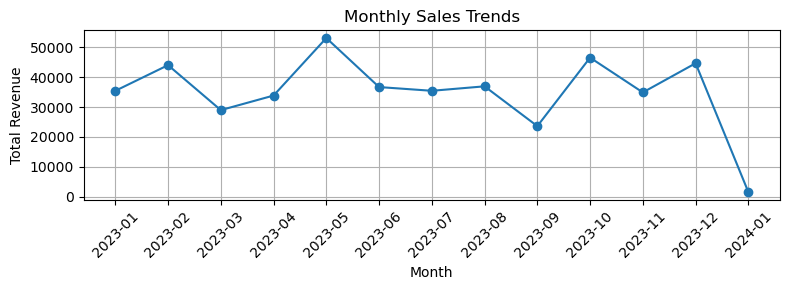

In [13]:
#sets the chart dimensions
plt.figure(figsize=(8, 3))

#creates a line chart using monthly sales data
plt.plot(
    #converts monthly period labels into strings for the x-axis
    monthly_sales.index.astype(str),
    #provides the corresponding monthly revenue values for the y-axis
    monthly_sales.values,
    #adds circular markers to each data point
    marker='o'
    
)
#sets the chart title
plt.title('Monthly Sales Trends')
#label the x-axis 
plt.xlabel('Month')
#label the y-axis
plt.ylabel('Total Revenue')
#rotates month labels for readability
plt.xticks(rotation=45)
#adds gridlines to make values easier to compare
plt.grid(True)
#adjusts spacing to prevent labels from being cut off
plt.tight_layout()

#displays the chart
plt.show()


### Monthly Sales Trend Analysis

The monthly sales analysis shows fluctuations in revenue throughout 2023, indicating that sales performance varied from month to month.

- **Highest revenue:** May 2023 recorded the highest monthly revenue of **53,150**.
- **Lowest revenue:** September 2023 recorded the lowest monthly revenue among the complete months, at **23,620**.
- **Revenue fluctuations:** Revenue increased considerably from April to May, followed by a decline in June and July. September experienced another decline, while October showed a strong recovery.
- **Year-end performance:** Revenue increased in October and remained relatively strong in November and December.

**Key observation:** May was the strongest sales month, whereas September was the weakest among the complete months analyzed. These fluctuations suggest variations in monthly sales performance that could be explored further through product category and transaction analysis.

**Data limitation:** January 2024 contains only four transactions, so its revenue should not be directly compared with the complete months of 2023.

In [14]:
#groups dates into quarterly periods (Q1, Q2, Q3, and Q4)
quarterly_sales = df.groupby(
    df['Date'].dt.to_period('Q')
)['Total Amount'].sum()
quarterly_sales 

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
2024Q1      1530
Freq: Q-DEC, Name: Total Amount, dtype: int64

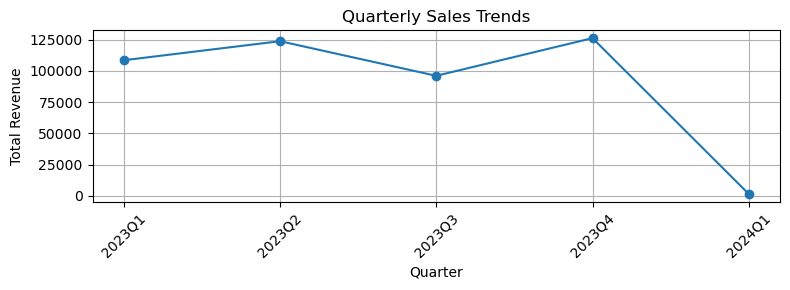

In [15]:
plt.figure(figsize=(8, 3))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker='o',
)

plt.title('Quarterly Sales Trends')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

### Quarterly Sales Trend Analysis

The quarterly sales analysis reveals fluctuations in revenue throughout the observed period.

- **Highest revenue:** Q4 2023 recorded the highest quarterly revenue of **126,190**.
- **Lowest revenue:** Q3 2023 recorded the lowest revenue among the complete quarters, at **96,045**.
- **Q1 to Q2:** Revenue increased from 108,500 to 123,735, indicating improved sales performance.
- **Q2 to Q3:** Revenue declined by approximately 22.38%, representing a considerable decrease in quarterly sales.
- **Q3 to Q4:** Revenue recovered by approximately 31.39%, reaching the highest level of the year.

**Key observation:** Q4 demonstrated the strongest quarterly revenue performance in 2023, while Q3 experienced a noticeable decline. This suggests that the business had varying sales performance across quarters.

**Data limitation:** Q1 2024 contains January data only, so it represents an incomplete quarter and should not be directly compared with the complete quarters of 2023.

In [16]:
#defines the age intervals used to divide customers into groups
bins = [17, 29, 44, 59, 100]

#assigns a descriptive name to each age group
labels = [
    #'Young Adults',
    '18-29',
    #'Adults',
    '30-44',
    #'Middle-aged Adults',
    '45-59',
    #'Seniors'
    '60-100'
  
]
#categorizes each customer's age based on the specified intervals and labels
df['Age Group'] = pd.cut(

    df['Age'],
    bins=bins,
    labels=labels
)
df[['Age', 'Age Group']].head(10)

,Age,Age Group
0,34,30-44
1,26,18-29
2,50,45-59
3,37,30-44
4,30,30-44
5,45,45-59
6,46,45-59
7,30,30-44
8,63,60-100
9,52,45-59


In [17]:
#counts how many records belong to each age group & sorts the results by the category index
age_distribution = df['Age Group'].value_counts().sort_index()

age_distribution

Age Group
18-29     251
30-44     308
45-59     326
60-100    115
Name: count, dtype: int64

In [18]:
age_percentage = df['Age Group'].value_counts(
    normalize=True
).sort_index() * 100

print(age_percentage)

Age Group
18-29     25.1
30-44     30.8
45-59     32.6
60-100    11.5
Name: proportion, dtype: float64


In [19]:
unique_customers = df['Customer ID'].nunique()
print(unique_customers)

1000


In [20]:
duplicate_customers= df['Customer ID'].duplicated().sum()
print(duplicate_customers)

0


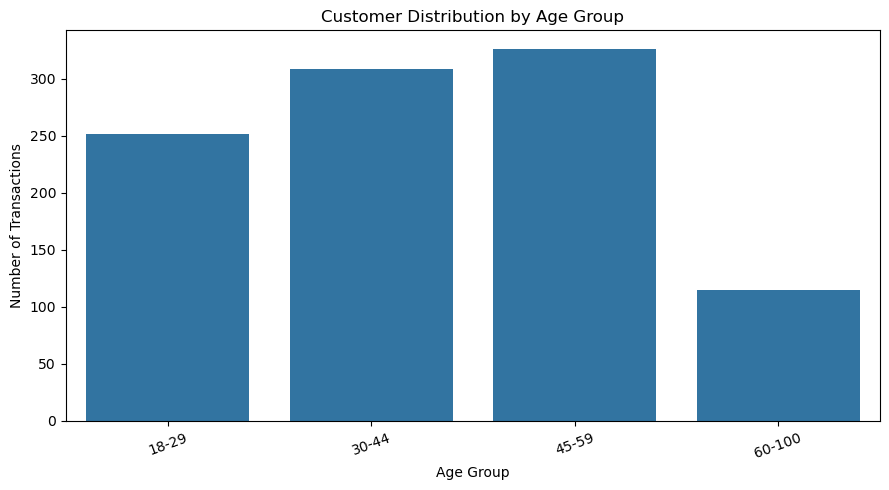

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Age Group',
    order=labels
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Customer Age Group Distribution

The age distribution analysis shows how transaction records are distributed across four age groups.

- **45–59:** This group represents the largest share, with 326 transactions (32.6%).
- **30–44:** The second-largest group, accounting for 308 transactions (30.8%).
- **18–29:** Represents 251 transactions (25.1%).
- **60–100:** Has the lowest representation, with 115 transactions (11.5%).

**Key observation:** The 30–59 age range accounts for 63.4% of all transaction records, indicating that these age groups contribute the largest share of recorded purchasing activity.

**Business insight:** The retailer could explore targeted marketing strategies for the 30–59 age groups while also investigating opportunities to increase engagement among younger and older age segments.

**Note:** Each Customer ID appears only once in this dataset. Therefore, the transaction counts also represent the number of unique customers in the dataset.

each customer appears only once in the dataset, with no repeated customer IDs.

In [22]:
df['Gender'].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

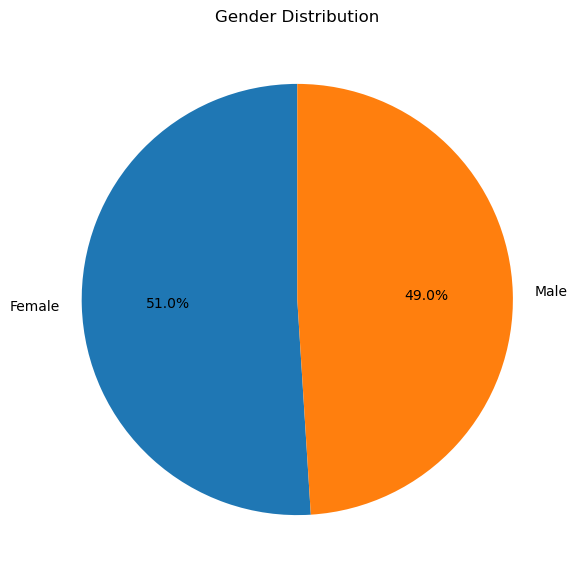

In [23]:
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.show()

### Gender Distribution Analysis

The gender distribution analysis shows a relatively balanced representation of female and male transaction records.

- **Female:** 510 transactions, representing 51% of the total.
- **Male:** 490 transactions, representing 49% of the total.

**Key observation:** Female transaction records account for a slightly higher proportion than male records. However, the difference is small, indicating a nearly balanced gender distribution.

**Business insight:** The retailer should consider maintaining marketing strategies that appeal to both gender groups rather than focusing heavily on one group.

**Note:** These figures represent transaction records, not necessarily the number of unique female and male customers.

In [24]:
category_counts = df['Product Category'].value_counts()

category_counts

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

In [25]:
category_quantity = df.groupby(
    'Product Category'
)['Quantity'].sum().sort_values(ascending=False)

category_quantity

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

In [26]:
category_revenue = df.groupby('Product Category')['Total Amount'].sum().sort_values(
    ascending=False
)

category_revenue

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

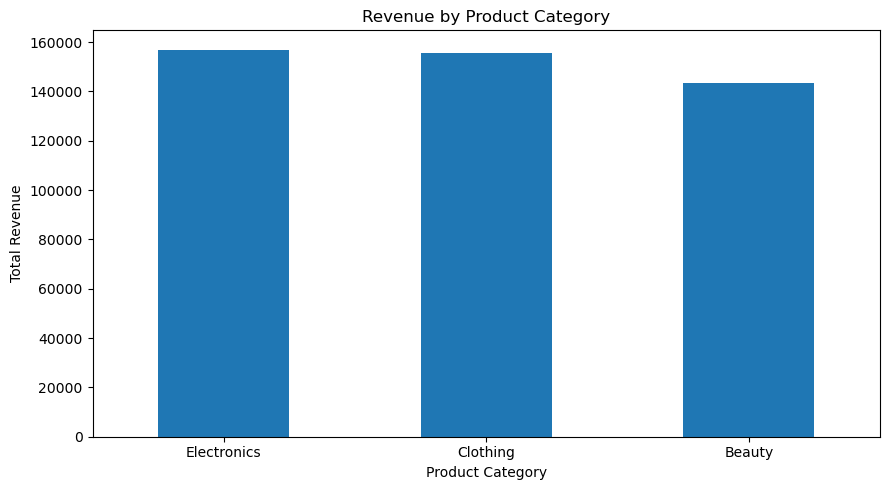

In [27]:
plt.figure(figsize=(9, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Product Category Analysis

Product performance was analyzed using transaction frequency, total revenue, and total quantity sold to understand the contribution of each product category.

**1. Transaction Frequency**

- Clothing recorded the highest number of transactions, with 351 records.
- Electronics followed with 342 transactions.
- Beauty recorded the lowest number, with 307 transactions.

**2. Revenue by Product Category**

- Electronics generated the highest revenue of **156,905**.
- Clothing followed closely with **155,580**.
- Beauty generated the lowest revenue of **143,515**.

**3. Quantity Sold by Product Category**

- Clothing recorded the highest sales volume, with 894 units sold.
- Electronics followed with 849 units.
- Beauty recorded the lowest quantity, with 771 units.

**Key Insights**

- Clothing leads in both transaction frequency and total quantity sold.
- Electronics generates the highest total revenue despite selling fewer units than Clothing.
- Beauty has the lowest total revenue and sales volume, but its average revenue per unit is relatively high.

**Business Recommendations**

- Maintain effective inventory planning for Clothing, which recorded the highest sales volume.
- Monitor Electronics performance because it generates the highest total revenue.
- Explore opportunities to improve Beauty category sales volume while maintaining its revenue contribution.

**Data Limitation:** The dataset contains product categories rather than individual product names or identifiers. Therefore, identifying the top 10 best-selling individual products is not possible. This analysis uses category-level sales volume as an alternative.

In [28]:
#filter transactions to include only 2023
df_2023 = df[df['Date'].dt.year == 2023]

#calculate monthly revenue by product category
monthly_category_sales = df_2023.groupby(
    [df_2023['Date'].dt.to_period('M'), 'Product Category']
)['Total Amount'].sum().unstack()

monthly_category_sales


Product Category,Beauty,Clothing,Electronics
Date,,,
2023-01,12430,13125,9895
2023-02,14035,14560,15465
2023-03,10545,15065,3380
2023-04,11905,13940,8025
2023-05,12450,17455,23245
2023-06,10995,10170,15550
2023-07,16090,8250,11125
2023-08,9790,12455,14715
2023-09,6320,9975,7325


<Figure size 1200x600 with 0 Axes>

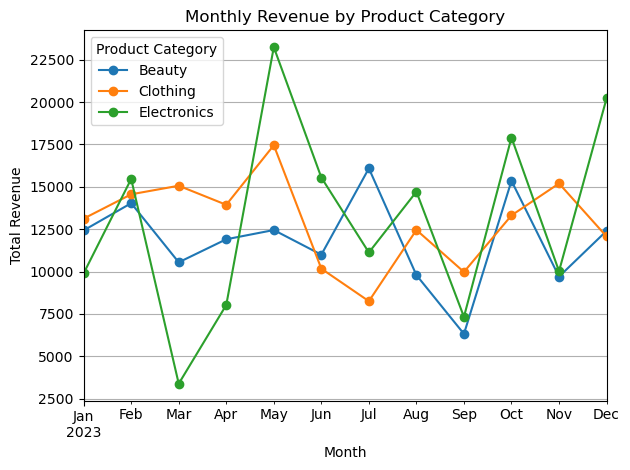

In [29]:
plt.figure(figsize=((12, 6)))

monthly_category_sales.plot(
    kind='line',
    marker='o',
)

plt.title('Monthly Revenue by Product Category')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.legend(title='Product Category')
plt.grid(True)
plt.tight_layout()
plt.show()

### Monthly Revenue by Product Category

This analysis compares monthly revenue across Beauty, Clothing, and Electronics to identify category-level sales patterns over time.

**Key observations:**

- **Beauty:** Recorded its highest monthly revenue in July 2023 (16,090).
- **Clothing:** Recorded its highest monthly revenue in May 2023 (17,455).
- **Electronics:** Recorded its highest monthly revenue in May 2023 (23,245).
- **Monthly fluctuations:** Revenue varied across all three categories, with September showing relatively low revenue across categories.

**Key insight:** Electronics generated the highest monthly category revenue in May 2023, while each category experienced different monthly performance patterns.

**Business implication:** Monitor category-level revenue each month to identify changes in performance and support inventory planning and targeted sales strategies.

**Data limitation:** January 2024 contains only four transactions, making it incomplete for monthly comparisons.

In [30]:
numeric_df = df.select_dtypes(include='number')

numeric_df.head()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
0,1,34,3,50,150
1,2,26,2,500,1000
2,3,50,1,30,30
3,4,37,1,500,500
4,5,30,2,50,100


In [31]:
numeric_df = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]
numeric_df.head()

,Age,Quantity,Price per Unit,Total Amount
0,34,3,50,150
1,26,2,500,1000
2,50,1,30,30
3,37,1,500,500
4,30,2,50,100


In [32]:
correlation_matrix = numeric_df.corr()

correlation_matrix

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


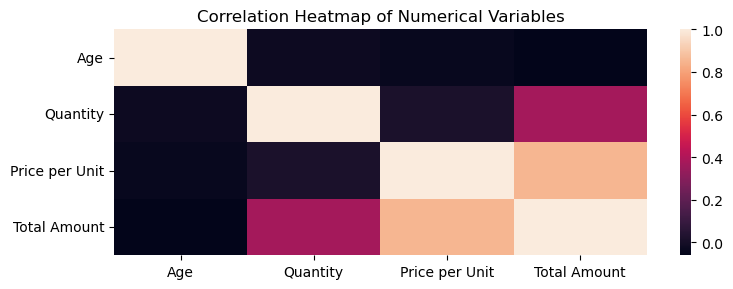

In [33]:
plt.figure(figsize=(8, 3))

sns.heatmap(
    correlation_matrix,
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

### Correlation Analysis

A correlation matrix was calculated to examine the linear relationships between numerical variables in the retail sales dataset. A heatmap was used to visualize the strength and direction of these relationships.

**Key Findings**

- **Price per Unit and Total Amount (0.85):** A strong positive correlation indicates that higher-priced products tend to be associated with higher transaction amounts.
- **Quantity and Total Amount (0.37):** A moderate positive correlation suggests that purchasing more units is generally associated with higher transaction amounts.
- **Age and Total Amount (-0.06):** A very weak negative correlation indicates little linear association between customer age and transaction amount.
- **Age and other numerical variables:** Age has very weak correlations with quantity and price per unit.

**Key Observation:** Price per Unit has the strongest positive correlation with Total Amount, followed by Quantity. This suggests that product price and purchase quantity are important factors associated with transaction value.

**Data Consideration:** Total Amount is calculated from Quantity multiplied by Price per Unit in this dataset. Therefore, its positive correlations with these two variables are partly expected and should not be interpreted as independent evidence of causation.

Correlation measures linear association and does not establish cause and effect.

# Conclusion and Business Recommendations

## Conclusion

The exploratory data analysis (EDA) of the retail sales dataset revealed useful patterns in revenue performance, customer demographics, and product category sales.

The main findings include:

- **Sales Trends:** May 2023 recorded the highest monthly revenue (53,150), while Q4 2023 recorded the highest quarterly revenue (126,190).
- **Customer Demographics:** Customers aged 30–59 accounted for 63.4% of the customer base. Gender distribution was relatively balanced, with female customers representing 51% and male customers 49%.
- **Product Performance:** Electronics generated the highest total revenue (156,905), while Clothing recorded the highest quantity sold (894 units).
- **Correlation Analysis:** Price per Unit had a strong positive correlation with Total Amount (0.85), while Age had a very weak negative correlation with Total Amount (-0.06). The strong price correlation is partly expected because Total Amount is calculated using Quantity and Price per Unit. Correlation does not necessarily imply causation.

## Business Recommendations

Based on the findings, the following recommendations are proposed:

1. **Improve Inventory Planning for Clothing:** Since Clothing recorded the highest quantity sold (894 units), the business should monitor inventory levels and plan replenishment according to sales demand.

2. **Monitor Electronics Performance:** Since Electronics generated the highest total revenue (156,905), the business should regularly track revenue, quantity sold, and selling prices to understand and maintain its performance.

3. **Improve Beauty Sales Volume:** Beauty recorded the lowest total revenue (143,515) and quantity sold (771 units). The business could test targeted promotions and marketing campaigns to improve sales volume and measure their effectiveness.

4. **Develop Targeted Marketing Strategies:** Since customers aged 30–59 accounted for 63.4% of the customer base, the business could test targeted campaigns for these age groups while continuing to serve other customer segments.

## Limitations

- The dataset does not contain individual product names or product IDs, so an analysis of the top 10 individual products was not possible.
- Each Customer ID appears only once in the dataset. Therefore, the analysis cannot provide insights into repeat purchases or customer retention.
- January 2024 contains only four transactions, making it incomplete for comparison with full months.
- The dataset does not include product costs or profit margins, so profitability could not be evaluated.

## Final Remarks

Overall, this analysis provides an overview of retail sales performance, customer demographics, and product category trends. The findings can help the retailer improve inventory planning, monitor sales performance, and develop targeted marketing strategies.

Further analysis using product-level information, cost data, and repeat-purchase records would provide a more complete understanding of business performance.